In [1]:
# ===== CELL 1: Generate the HAPS link dataset =====
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

# --- Design assumptions (from the slides) ---
FREQ_GHZ = 28
HAPS_ALT_KM = 20
TX_DBM = 40          # 10 W
G_HAPS = 30          # dBi
G_USER = 35          # dBi
NOISE_FLOOR_DBM = -90

N_TRAJ = 150         # trajectories per scenario
N_STEPS = 60         # time steps per trajectory
MAX_RANGE_KM = 50    # footprint radius

rows = []
traj_id = 0
for scenario in ["clear_sky", "monsoon_rain"]:
    for _ in range(N_TRAJ):
        # User moves as a slow random walk across the footprint
        r0 = rng.uniform(1, MAX_RANGE_KM)
        steps = rng.normal(0, 0.8, N_STEPS)
        ground_km = np.clip(r0 + np.cumsum(steps), 1, MAX_RANGE_KM)

        # Geometry
        slant_km = np.sqrt(ground_km**2 + HAPS_ALT_KM**2)
        elev_deg = np.degrees(np.arctan2(HAPS_ALT_KM, ground_km))
        sin_el = np.sin(np.radians(elev_deg))

        # Free-space path loss (ITU-R P.525)
        fspl = 92.45 + 20*np.log10(FREQ_GHZ) + 20*np.log10(slant_km)

        # Rain-rate time series (mm/h), seeded
        if scenario == "monsoon_rain":
            x = np.zeros(N_STEPS)
            for t in range(1, N_STEPS):
                x[t] = 0.95*x[t-1] + rng.normal(0, 0.35)
            rain_rate = np.clip(np.exp(2.0 + x), 0, 100)
            gas_zenith, cloud_zenith = 0.40, 0.50
        else:
            rain_rate = np.zeros(N_STEPS)
            gas_zenith, cloud_zenith = 0.25, 0.0

        # Atmospheric losses (zenith value / sin(elevation))
        gas = gas_zenith / sin_el
        cloud = cloud_zenith / sin_el

        # Rain loss (simplified ITU-R P.838 / P.618 style)
        k, alpha = 0.20, 0.95
        gamma = k * rain_rate**alpha                  # dB/km
        eff_len = 0.6 * np.minimum(4.0 / sin_el, 15)  # km
        rain = gamma * eff_len

        # Scintillation and pointing jitter (seeded noise)
        scint = rng.normal(0, 0.3 / np.sqrt(sin_el))
        pointing = np.abs(rng.normal(0, 0.2, N_STEPS))

        total_loss = fspl + gas + cloud + rain + pointing - scint

        # Link budget
        pr_dbm = TX_DBM + G_HAPS + G_USER - total_loss
        snr = pr_dbm - NOISE_FLOOR_DBM

        # Noisy weather observation (what a sensor would report)
        rain_obs = np.clip(rain_rate + rng.normal(0, 2.0, N_STEPS), 0, None)

        for t in range(N_STEPS):
            rows.append({
                "trajectory_id": traj_id,
                "step": t,
                "scenario": scenario,
                "ground_km": ground_km[t],
                "elevation": elev_deg[t],
                "slant_range": slant_km[t],
                "noisy_rain_obs": rain_obs[t],
                "fspl": fspl[t],
                "snr_true": snr[t],
            })
        traj_id += 1

df = pd.DataFrame(rows)
df.to_csv("dataset.csv", index=False)

print("Rows:", len(df))
print("Elevation range:", round(df.elevation.min(), 1), "to", round(df.elevation.max(), 1), "deg")
print(df.groupby("scenario")["snr_true"].describe().round(1))
df.head()


Rows: 18000
Elevation range: 21.8 to 87.1 deg
               count  mean   std   min   25%   50%   75%   max
scenario                                                      
clear_sky     9000.0  43.0   2.8  36.7  40.4  43.2  45.5  48.2
monsoon_rain  9000.0  33.2  12.7 -67.0  30.3  36.1  40.9  46.5


,trajectory_id,step,scenario,ground_km,elevation,slant_range,noisy_rain_obs,fspl,snr_true
0,0,0,clear_sky,38.091859,27.701565,43.023130,0.438765,154.067201,40.211804
1,0,1,clear_sky,38.692220,27.334432,43.555572,0.000000,154.174035,40.309575
2,0,2,clear_sky,39.444672,26.886801,44.225356,2.212577,154.306587,40.130278
3,0,3,clear_sky,37.883844,27.830897,42.839066,0.857513,154.029961,40.579802
4,0,4,clear_sky,36.842100,28.495642,41.920643,3.071512,153.841719,40.907473


In [4]:
# ===== CELL 2 (v2): Baseline vs Hybrid + grouped conformal band =====
import numpy as np
import pandas as pd
import lightgbm as lgb

SEED = 42
rng = np.random.default_rng(SEED)

df = pd.read_csv("dataset.csv")
df["scen_code"] = (df.scenario == "monsoon_rain").astype(int)

TX_DBM, G_HAPS, G_USER, NOISE_FLOOR_DBM = 40, 30, 35, -90

# --- Split by whole trajectory: 60% train, 20% calibration, 20% test ---
ids = df.trajectory_id.unique()
rng.shuffle(ids)
n = len(ids)
train_ids = ids[: int(0.6 * n)]
calib_ids = ids[int(0.6 * n): int(0.8 * n)]
test_ids = ids[int(0.8 * n):]

LOW_BAND = 30
train = df[df.trajectory_id.isin(train_ids) & (df.elevation >= LOW_BAND)].copy()  # model never sees <30 deg
calib = df[df.trajectory_id.isin(calib_ids)].copy()                               # calibration sees all elevations
test = df[df.trajectory_id.isin(test_ids)].copy()

# --- BASELINE ---
def nominal_snr(d):
    return TX_DBM + G_HAPS + G_USER - d.fspl - NOISE_FLOOR_DBM

FIXED_LOSS = (nominal_snr(train) - train.snr_true).mean()
print("Fixed atmospheric loss used by baseline:", round(FIXED_LOSS, 2), "dB")

for d in (train, calib, test):
    d["baseline"] = nominal_snr(d) - FIXED_LOSS
    d["residual"] = d.snr_true - d.baseline

# --- HYBRID ---
FEATURES = ["elevation", "slant_range", "scen_code", "noisy_rain_obs"]
params = dict(n_estimators=300, learning_rate=0.05, num_leaves=31,
              random_state=SEED, verbose=-1)

mean_model = lgb.LGBMRegressor(**params).fit(train[FEATURES], train.residual)
lo_model = lgb.LGBMRegressor(objective="quantile", alpha=0.05, **params).fit(train[FEATURES], train.residual)
hi_model = lgb.LGBMRegressor(objective="quantile", alpha=0.95, **params).fit(train[FEATURES], train.residual)

# --- Grouped conformal calibration (scenario x elevation group) ---
def group_of(d):
    return d.scen_code * 2 + (d.elevation < LOW_BAND).astype(int)

calib["grp"] = group_of(calib)
test["grp"] = group_of(test)

lo_c = lo_model.predict(calib[FEATURES])
hi_c = hi_model.predict(calib[FEATURES])
scores = np.maximum(lo_c - calib.residual.values, calib.residual.values - hi_c)

q_by_grp = {}
for g in sorted(calib.grp.unique()):
    sc = scores[(calib.grp == g).values]
    level = min(1.0, np.ceil((len(sc) + 1) * 0.90) / len(sc))
    q_by_grp[g] = float(np.quantile(sc, level))
print("Conformal adjustment per group (0=clear>=30, 1=clear<30, 2=rain>=30, 3=rain<30):")
print({k: round(v, 2) for k, v in q_by_grp.items()})

test["q"] = test.grp.map(q_by_grp)

# --- Predict on held-out trajectories ---
test["hybrid"] = test.baseline + mean_model.predict(test[FEATURES])
test["lo"] = test.baseline + lo_model.predict(test[FEATURES]) - test.q
test["hi"] = test.baseline + hi_model.predict(test[FEATURES]) + test.q

def summarize(d, name):
    out = []
    for scen in ["clear_sky", "monsoon_rain"]:
        s = d[d.scenario == scen]
        out.append({
            "test_set": name,
            "scenario": scen,
            "rows": len(s),
            "MAE_baseline_dB": round((s.snr_true - s.baseline).abs().mean(), 2),
            "MAE_hybrid_dB": round((s.snr_true - s.hybrid).abs().mean(), 2),
            "coverage_90": round(((s.snr_true >= s.lo) & (s.snr_true <= s.hi)).mean(), 3),
            "avg_band_width_dB": round((s.hi - s.lo).mean(), 2),
        })
    return out

results = pd.DataFrame(
    summarize(test, "All held-out trajectories")
    + summarize(test[test.elevation < LOW_BAND], "Unseen low elevation (<30 deg)")
)
results.to_csv("metrics.csv", index=False)
test.to_csv("test_predictions.csv", index=False)

print()
print(results.to_string(index=False))

Fixed atmospheric loss used by baseline: 4.04 dB
Conformal adjustment per group (0=clear>=30, 1=clear<30, 2=rain>=30, 3=rain<30):
{np.int64(0): 0.1, np.int64(1): 0.31, np.int64(2): 0.3, np.int64(3): 2.8}

                      test_set     scenario  rows  MAE_baseline_dB  MAE_hybrid_dB  coverage_90  avg_band_width_dB
     All held-out trajectories    clear_sky  2220             3.45           0.35        0.912               1.63
     All held-out trajectories monsoon_rain  1380             5.61           1.58        0.876               6.30
Unseen low elevation (<30 deg)    clear_sky   757             3.30           0.41        0.921               2.08
Unseen low elevation (<30 deg) monsoon_rain   515             8.48           2.61        0.856              10.46


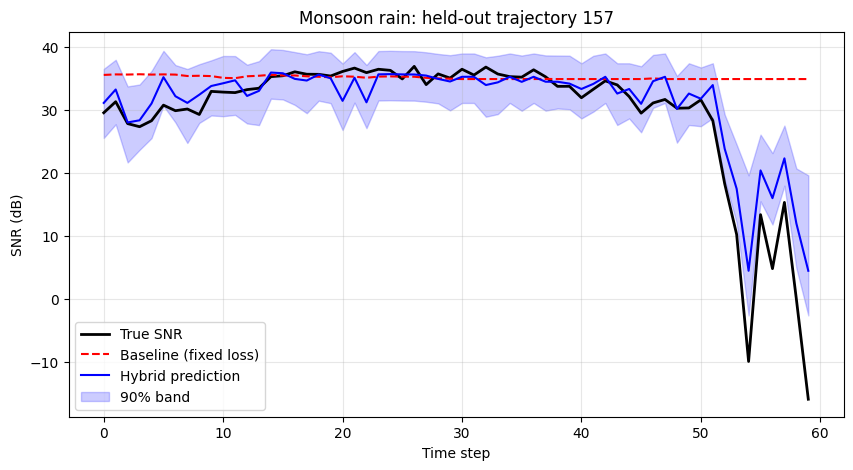

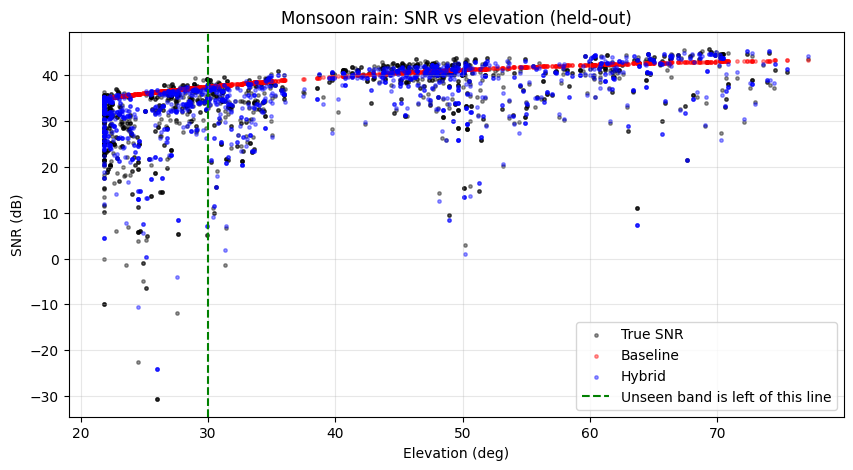

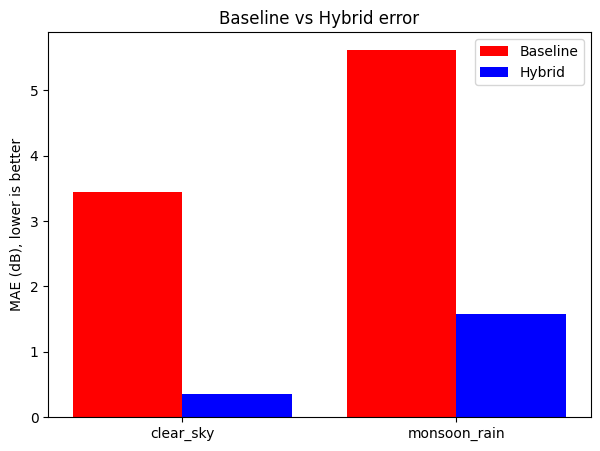

In [5]:
# ===== CELL 3: Charts for the demo =====
import matplotlib.pyplot as plt

res = pd.read_csv("metrics.csv")

# ---------- Chart 1: one rainy trajectory over time ----------
tid = test[test.scenario == "monsoon_rain"].trajectory_id.iloc[0]
s = test[test.trajectory_id == tid].sort_values("step")

plt.figure(figsize=(10, 5))
plt.plot(s.step, s.snr_true, "k-", label="True SNR", linewidth=2)
plt.plot(s.step, s.baseline, "r--", label="Baseline (fixed loss)")
plt.plot(s.step, s.hybrid, "b-", label="Hybrid prediction")
plt.fill_between(s.step, s.lo, s.hi, color="blue", alpha=0.2, label="90% band")
plt.xlabel("Time step")
plt.ylabel("SNR (dB)")
plt.title(f"Monsoon rain: held-out trajectory {tid}")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("chart1_trajectory.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Chart 2: SNR vs elevation (shows the unseen low band) ----------
m = test[test.scenario == "monsoon_rain"].sample(1500, random_state=42, replace=True)
plt.figure(figsize=(10, 5))
plt.scatter(m.elevation, m.snr_true, s=6, c="k", alpha=0.4, label="True SNR")
plt.scatter(m.elevation, m.baseline, s=6, c="r", alpha=0.4, label="Baseline")
plt.scatter(m.elevation, m.hybrid, s=6, c="b", alpha=0.4, label="Hybrid")
plt.axvline(30, color="green", linestyle="--", label="Unseen band is left of this line")
plt.xlabel("Elevation (deg)")
plt.ylabel("SNR (dB)")
plt.title("Monsoon rain: SNR vs elevation (held-out)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("chart2_elevation.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Chart 3: MAE comparison ----------
a = res[res.test_set == "All held-out trajectories"]
x = np.arange(len(a))
plt.figure(figsize=(7, 5))
plt.bar(x - 0.2, a.MAE_baseline_dB, 0.4, color="red", label="Baseline")
plt.bar(x + 0.2, a.MAE_hybrid_dB, 0.4, color="blue", label="Hybrid")
plt.xticks(x, a.scenario)
plt.ylabel("MAE (dB), lower is better")
plt.title("Baseline vs Hybrid error")
plt.legend()
plt.savefig("chart3_mae.png", dpi=150, bbox_inches="tight")
plt.show()